# DSCI 552 — Homework 8

Name: Zhicheng Zhang  
GitHub Username: Hustzz-Max  
USC ID: 8006795737

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

### 1(a). Load the data

I used the 30 measurements as inputs. Malignant is the positive class (1), and benign is 0.
[UCI breast cancer data](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic)

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import Parallel, delayed
from scipy.special import softmax
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.svm import LinearSVC
from threadpoolctl import threadpool_limits

data_dir = Path('../data') if Path('../data').is_dir() else Path('data')
cancer = pd.read_csv(data_dir / 'wdbc.data', header=None)
X = cancer.iloc[:, 2:].to_numpy()
y = (cancer.iloc[:, 1] == 'M').to_numpy(dtype=int)
print(f'{len(y)} rows, {X.shape[1]} features; B={sum(y == 0)}, M={sum(y == 1)}')

569 rows, 30 features; B=357, M=212


### 1(b)(i–ii). Supervised SVM and self-training

I repeated each method on the same 30 stratified 80/20 splits. Min-max scaling is fitted on the available training data. Five-fold CV chooses C from 0.01, 0.1, 1, and 10 by accuracy. Larger C puts more weight on fitting the training labels.

For self-training, I randomly labeled half of each training class, rounded down. After choosing C on those labels, I kept it fixed. At each step I added the single unlabeled point with the largest absolute decision score, assigned its predicted label, and refit. Its true label is used only when scoring the final model.

[L1 SVM](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html) · [Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html)

In [2]:
def tune_svm(features, labels, seed, scaler=MinMaxScaler, tolerance=0.001):
    model = make_pipeline(
        scaler(),
        LinearSVC(penalty='l1', dual=False, tol=tolerance,
                  max_iter=300000, random_state=seed)
    )
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    search = GridSearchCV(model, {'linearsvc__C': [0.01, 0.1, 1, 10]},
                          scoring='accuracy', cv=folds, n_jobs=1, error_score='raise')
    return search.fit(features, labels).best_estimator_

def self_train(features, labels, seed):
    rng = np.random.default_rng(seed)
    labeled = np.concatenate([
        rng.choice(np.flatnonzero(labels == value),
                   size=sum(labels == value) // 2, replace=False)
        for value in (0, 1)
    ])
    remaining = np.setdiff1d(np.arange(len(labels)), labeled)
    working_y = labels[labeled].copy()
    model = tune_svm(features[labeled], working_y, seed)
    while len(remaining):
        scores = model.decision_function(features[remaining])
        pick = np.argmax(np.abs(scores))
        labeled = np.append(labeled, remaining[pick])
        working_y = np.append(working_y, int(scores[pick] >= 0))
        remaining = np.delete(remaining, pick)
        model.fit(features[labeled], working_y)
    return model

### 1(b)(iii–iv). Clustering

I used k=2 for k-means, with 30 random initializations and the smallest resulting inertia. More starts reduce the chance of a poor local solution, though a global optimum is not guaranteed. For each center, the closest 30 training points vote for its class. A tie goes to benign. Test points use their nearest center. Softmax of negative squared distances gives an ROC ranking score.

Spectral clustering forms an RBF similarity graph and uses its eigenvectors to group connected points. I used gamma=1 and fit_predict. For test evaluation I clustered the normalized training and unlabeled test features together, then used training labels to label each cluster by majority vote. The malignant fraction among those training members is its ROC score. This is a transductive evaluation: the graph includes test features. Cluster construction uses features, and label assignment uses training labels.

[Spectral clustering](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.SpectralClustering.html)

In [3]:
def clustering_scores(train_x, train_y, test_x, seed):
    scaler = MinMaxScaler().fit(train_x)
    train_z, test_z = scaler.transform(train_x), scaler.transform(test_x)
    kmeans = KMeans(n_clusters=2, init='random', n_init=30, random_state=seed)
    kmeans.fit(train_z)
    train_d, test_d = kmeans.transform(train_z), kmeans.transform(test_z)
    rates = np.array([train_y[np.argsort(train_d[:, j])[:30]].mean() for j in (0, 1)])
    cluster_classes = (rates > 0.5).astype(int)
    km = []
    for distances in (train_d, test_d):
        predicted = cluster_classes[distances.argmin(axis=1)]
        scores = softmax(-distances ** 2, axis=1) @ cluster_classes
        km.append((predicted, scores))

    graph_x = np.vstack([train_z, test_z])
    spectral = SpectralClustering(n_clusters=2, affinity='rbf', gamma=1,
                                  n_init=30, random_state=seed, eigen_solver='arpack')
    clusters = spectral.fit_predict(graph_x)
    train_clusters = clusters[:len(train_y)]
    rates = np.array([
        train_y[train_clusters == j].mean() if np.any(train_clusters == j)
        else train_y.mean() for j in (0, 1)
    ])
    sp = [((rates[c] > 0.5).astype(int), rates[c])
          for c in (train_clusters, clusters[len(train_y):])]
    return {'K-means': km, 'Spectral': sp}

def metrics(actual, predicted, score):
    return {'Accuracy': accuracy_score(actual, predicted),
            'Precision': precision_score(actual, predicted, zero_division=0),
            'Recall': recall_score(actual, predicted, zero_division=0),
            'F1': f1_score(actual, predicted, zero_division=0),
            'AUC': roc_auc_score(actual, score)}

def cancer_run(seed):
    with threadpool_limits(limits=1):
        train_x, test_x, train_y, test_y = train_test_split(
            X, y, test_size=0.2, random_state=seed, stratify=y
        )
        predictions = {}
        for name, model in [('Supervised', tune_svm(train_x, train_y, seed)),
                            ('Self-training', self_train(train_x, train_y, seed))]:
            predictions[name] = [
                (model.predict(features), model.decision_function(features))
                for features in (train_x, test_x)
            ]
        predictions.update(clustering_scores(train_x, train_y, test_x, seed))
        rows = []
        for name, splits in predictions.items():
            for split, actual, (predicted, scores) in zip(
                    ('Train', 'Test'), (train_y, test_y), splits):
                rows.append({'Run': seed, 'Method': name, 'Split': split,
                             **metrics(actual, predicted, scores)})
        return rows, (train_y, test_y, predictions)

In [4]:
cancer_runs = Parallel(n_jobs=4, backend='loky', verbose=5)(
    delayed(cancer_run)(seed) for seed in range(42, 72)
)
cancer_results = pd.DataFrame([row for result, _ in cancer_runs for row in result])
cancer_means = cancer_results.groupby(['Method', 'Split']).mean(numeric_only=True)
display(cancer_means.drop(columns='Run').round(4))

Accuracy  Precision  Recall      F1     AUC
Method        Split                                             
K-means       Test     0.9295     0.9501  0.8548  0.8989  0.9792
              Train    0.9248     0.9488  0.8449  0.8936  0.9784
Self-training Test     0.9687     0.9672  0.9484  0.9570  0.9931
              Train    0.9762     0.9809  0.9551  0.9677  0.9945
Spectral      Test     0.8544     0.9162  0.6167  0.7352  0.8049
              Train    0.8399     0.9152  0.5829  0.7120  0.7880
Supervised    Test     0.9734     0.9763  0.9516  0.9634  0.9935
              Train    0.9858     0.9924  0.9694  0.9807  0.9975

### 1(b). ROC curves and confusion matrices for run 42

For each method and split, the confusion matrix entries are listed as TN, FP, FN, TP. Malignant is the positive class.

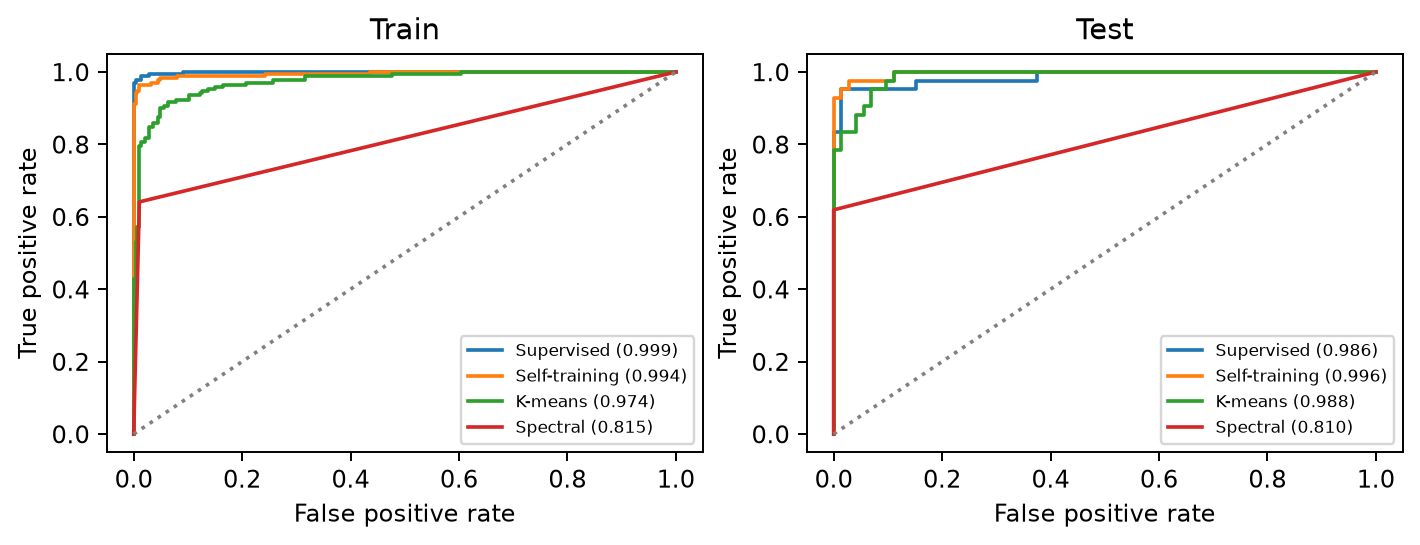

,,TN,FP,FN,TP
Method,Split,,,,
Supervised,Train,284,1,4,166
Self-training,Train,282,3,7,163
K-means,Train,274,11,24,146
Spectral,Train,282,3,61,109
Supervised,Test,71,1,4,38
Self-training,Test,70,2,2,40
K-means,Test,71,1,8,34
Spectral,Test,72,0,16,26


In [5]:
train_y, test_y, example = cancer_runs[0][1]
fig, axes = plt.subplots(1, 2, figsize=(8, 3), layout='constrained')
matrix_rows = []
for i, (split, actual) in enumerate([('Train', train_y), ('Test', test_y)]):
    for name, predictions in example.items():
        predicted, score = predictions[i]
        fpr, tpr, _ = roc_curve(actual, score)
        axes[i].plot(fpr, tpr, label=f'{name} ({roc_auc_score(actual, score):.3f})')
        tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
        matrix_rows.append([name, split, tn, fp, fn, tp])
    axes[i].plot([0, 1], [0, 1], ':', color='gray')
    axes[i].set(title=split, xlabel='False positive rate', ylabel='True positive rate')
    axes[i].legend(fontsize=7, loc='lower right')
plt.show()
display(pd.DataFrame(matrix_rows, columns=['Method', 'Split', 'TN', 'FP', 'FN', 'TP'])
        .set_index(['Method', 'Split']))

### 1(b)(v). Comparison

Supervised learning had the highest mean test accuracy (97.34%), followed by self-training (96.87%) and k-means (92.95%). Spectral clustering reached 85.44% in the transductive setting. Self-training can reinforce mistakes, while clusters can differ from the diagnosis classes.

## 2. Active Learning Using Support Vector Machines

### 2(a). Load and split the data

I randomly reserved 472 banknotes for testing and used the remaining 900 as the training pool. This split stays fixed across the 50 runs.
[UCI banknote data](https://archive.ics.uci.edu/dataset/267/banknote+authentication)

In [6]:
banknotes = pd.read_csv(data_dir / 'data_banknote_authentication.txt', header=None)
bank_x, bank_y = banknotes.iloc[:, :4].to_numpy(), banknotes.iloc[:, 4].to_numpy()
pool_x, held_x, pool_y, held_y = train_test_split(
    bank_x, bank_y, train_size=900, test_size=472, random_state=42
)
print(f'{len(pool_y)} pool rows, {len(held_y)} test rows')

900 pool rows, 472 test rows


### 2(b). Passive and active learning

Each run starts with five randomly selected notes from each class, so five-fold stratified CV is possible with ten labels. Both methods share this initial set. Passive learning adds ten random unused notes. Active learning adds the ten unused notes closest to the current hyperplane. Within one model, absolute decision scores and hyperplane distances give the same ranking.

I retuned C by five-fold CV after every addition, using the same grid as in Question 1. Here I standardized the four features and used solver tolerance 0.01. Every labeled set has its own fitted scaler. Once a note enters the labeled set, it stays there. Each method fits 90 final models per run, at sizes 10, 20, ..., 900.

In [7]:
def banknote_run(seed):
    with threadpool_limits(limits=1):
        rng = np.random.default_rng(seed)
        initial = np.concatenate([
            rng.choice(np.flatnonzero(pool_y == value), size=5, replace=False)
            for value in (0, 1)
        ])
        unused = np.setdiff1d(np.arange(900), initial)
        random_order = rng.permutation(unused)
        errors = np.empty((2, 90))
        for method in (0, 1):
            selected, remaining = initial.copy(), unused.copy()
            for step in range(90):
                fit_rows = np.sort(selected)
                model = tune_svm(pool_x[fit_rows], pool_y[fit_rows], seed,
                                 StandardScaler, tolerance=0.01)
                errors[method, step] = np.mean(model.predict(held_x) != held_y)
                if step == 89:
                    break
                if method == 0:
                    selected = np.concatenate([initial, random_order[:10 * (step + 1)]])
                else:
                    distance = np.abs(model.decision_function(pool_x[remaining]))
                    closest = np.argsort(distance, kind='stable')[:10]
                    selected = np.append(selected, remaining[closest])
                    remaining = np.delete(remaining, closest)
        return errors

banknote_errors = np.array(Parallel(n_jobs=4, backend='loky', verbose=5)(
    delayed(banknote_run)(seed) for seed in range(42, 92)
))
print('Runs, methods, training sizes:', banknote_errors.shape)

Runs, methods, training sizes: (50, 2, 90)


### 2(c). Average learning curves

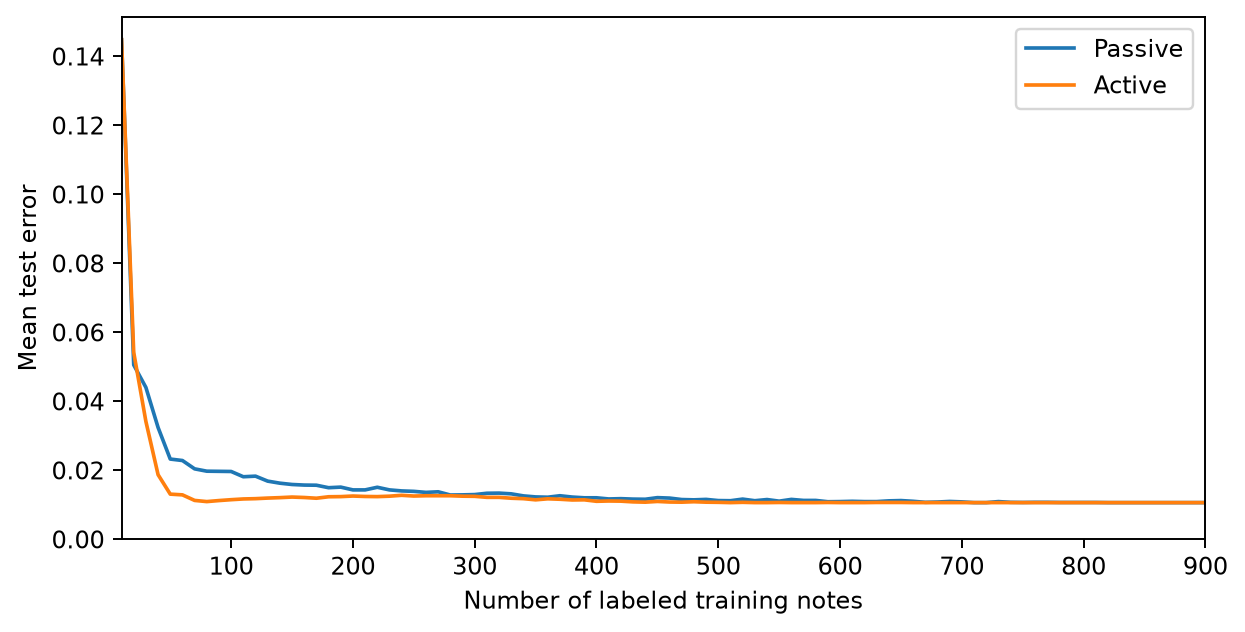

,Passive,Active
Labeled notes,,
10,0.1448,0.1448
50,0.0232,0.0131
100,0.0196,0.0114
200,0.0143,0.0125
500,0.0112,0.0107
900,0.0106,0.0106


In [8]:
sizes = np.arange(10, 901, 10)
mean_errors = banknote_errors.mean(axis=0)
fig, ax = plt.subplots(figsize=(7, 3.5), layout='constrained')
for i, name in enumerate(['Passive', 'Active']):
    ax.plot(sizes, mean_errors[i], label=name)
ax.set(xlabel='Number of labeled training notes', ylabel='Mean test error',
       xlim=(10, 900), ylim=(0, None))
ax.legend()
plt.show()
show_sizes = [10, 50, 100, 200, 500, 900]
learning_table = pd.DataFrame(mean_errors.T, index=sizes, columns=['Passive', 'Active'])
display(learning_table.loc[show_sizes].rename_axis('Labeled notes').round(4))

Active learning had the lower error averaged over all 90 training sizes. At 100 labels, passive and active error were 1.96% and 1.14%. At 900 labels, both reached 1.06%. Active learning focuses the next labels on cases near the boundary. Both methods eventually use the full pool.

Some SVM fits reached the 300,000-iteration limit. Their returned numerical fits are used in these averages.